# Positive Affect

> Do you feel happiness, laughter and enjoyment

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Default

In [2]:
COLUMN = columns['PA']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Summary

In [4]:
train_df[COLUMN].info()

PositiveAffect_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
PositiveAffect_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

PositiveAffect_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Positive affect
Non-Null Count  Dtype  
--------------  -----  
1542 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Positive affect,1542.0,0.708551,0.108029,0.322,0.623,0.721,0.798,0.944,2


In [5]:
missing_values_PositiveAffect = train_df[COLUMN].isna().sum()
count_PositiveAffect = train_df[COLUMN].count()

print(f"{missing_values_PositiveAffect} missing values out of {count_PositiveAffect} -> {round(missing_values_PositiveAffect / count_PositiveAffect, 2)}%")

17 missing values out of 1542 -> 0.01%


# Plots

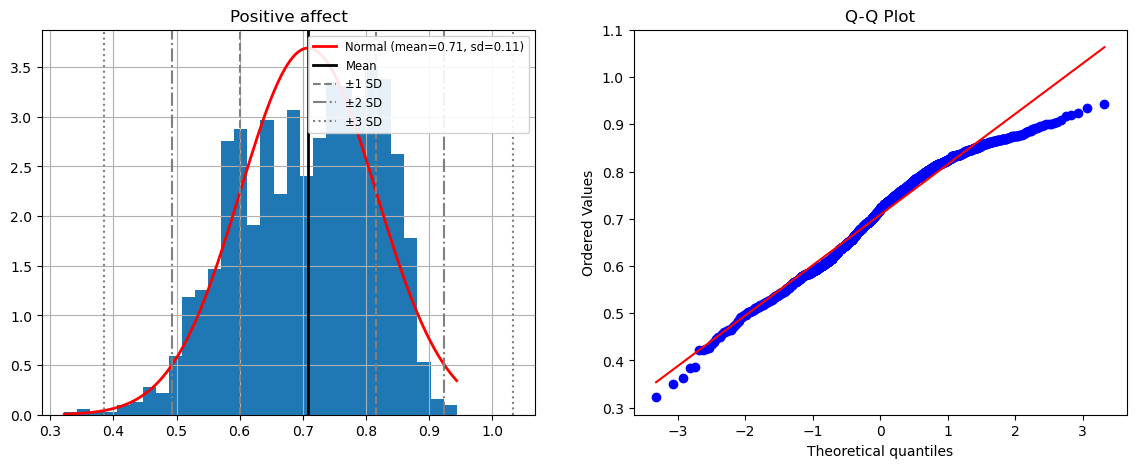

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Positive affect'}, xlabel='Positive affect', ylabel='Life Ladder'>

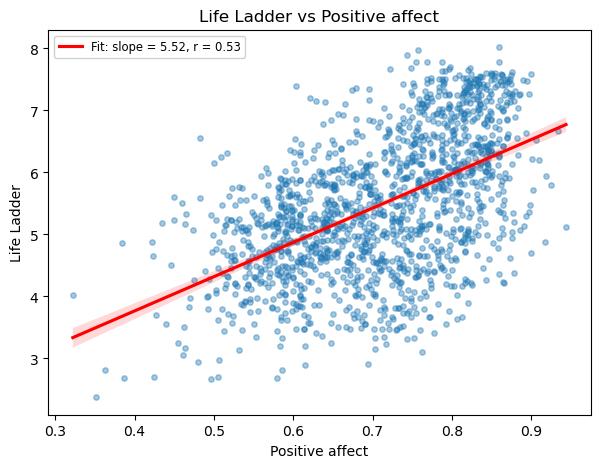

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Positive affect",
	target=TARGET,
)

In [8]:
correlation_to_target_PositiveAffect = train_df[TARGET].corr(train_df["Positive affect"])
print(f"Correlation: {correlation_to_target_PositiveAffect:.3f}")

Correlation: 0.535


# Skew & Kurtosis

In [9]:
PositiveAffectSkew = train_df[COLUMN].skew()
PositiveAffectSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Positive affect"])
PositiveAffectKurtosis = train_df[COLUMN].kurt()
PositiveAffectKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'Positive Affect Skew: {PositiveAffectSkew:.3f} -> {PositiveAffectSkew_RuleOfThumb}')
print(f'Positive Affect Kurtosis: {PositiveAffectKurtosis:.3f} -> {PositiveAffectKurtosis_RuleOfThumb}')

Positive Affect Skew: -0.348 -> Roughly symmetric
Positive Affect Kurtosis: -0.607 -> Mesokurtic (near-normal tails)


In [10]:
PositiveAffectSkewTransformed = compare_all_transforms(series=train_df["Positive affect"])
PositiveAffectSkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
quantile,-0.347713,0.000299,3.480121e-01,-0.607233,0.636679,1.243913,Roughly symmetric
rank,-0.347713,-0.002081,3.456322e-01,-0.607233,-1.200698,-0.593465,Roughly symmetric
square,-0.347713,-0.064969,2.827436e-01,-0.607233,-0.915988,-0.308755,Roughly symmetric
yeo_johnson,-0.347713,-0.066253,2.814599e-01,-0.607233,-0.894439,-0.287206,Roughly symmetric
logit,-0.347713,0.073455,4.211675e-01,-0.607233,-0.602445,0.004789,Roughly symmetric
box_cox,-0.347713,-0.091632,2.560813e-01,-0.607233,-0.900500,-0.293267,Roughly symmetric
arcsine_sqrt,-0.347713,-0.153935,1.937775e-01,-0.607233,-0.687620,-0.080386,Roughly symmetric
cube,-0.347713,0.175129,5.228420e-01,-0.607233,-0.937077,-0.329843,Roughly symmetric
reflect_log,-0.347713,0.190250,5.379628e-01,-0.607233,-0.785736,-0.178503,Roughly symmetric


---

### Notes / Observations
#### General
- 17 missing values (1.1% of rows).
- A 0 to 1 share ranging from 0.32 to 0.94 (mean 0.71, median 0.72), with only 2 IQR outliers.
- Mildly left skewed (skew -0.35, kurtosis -0.61), with two soft humps (near 0.6 and 0.8) that show up in the scatter matrix density curve.
- Moderate positive link to happiness (r = 0.53): a steady upward trend, but with wide spread.
- Overlaps with Freedom (r = 0.61) much more than with GDP (r = 0.30).
- **Takeaway:** mid strength predictor that captures a day to day mood signal separate from wealth.

#### Transforming
- Not needed: skew and kurtosis are both inside the "normal" rule of thumb ranges.
- If wanted, square (skew -0.07) or yeo_johnson (-0.07) make it almost perfectly symmetric.
- log and sqrt make it worse (-0.72, -0.52).

#### Scaling
- Already in a 0 to 1 range, but StandardScaler keeps it consistent with the other features.
- Almost no outliers, so MinMaxScaler would also be safe.

#### Imputing
- 12 of the 17 missing rows are also missing Negative affect (same survey questions), so Negative affect cannot help fill these.
- Freedom (r = 0.61) is the best source for IterativeImputer or KNNImputer.
- Mean (0.709) and median (0.721) are close, so a median SimpleImputer is also fine.